# Task 13 — Attrition Model V2: Beat the Baseline Honestly

This notebook reuses the Task 2 feature builder and reproduces the Task 3 five-fold outer evaluation protocol. Gradient-boosting tuning is nested inside each outer training fold so the outer test fold is not used for hyperparameter selection.

**Primary selection metric:** average precision (PR-AUC), because the attrition target is imbalanced.

**Models:** Task 3 Dummy, balanced Logistic Regression and depth-4 Decision Tree baselines; LightGBM and XGBoost candidates.

**Responsible-use boundary:** this model is decision support for supportive human review only, not an automated employment decision system. Do not open or use unlocked validation labels during training or tuning.

In [1]:
%pip install lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 5.1 MB/s eta 0:00:00a 0:00:01

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
!apt-get update -qq
!apt-get install -y libgomp1

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  libgomp1
0 upgraded, 1 newly installed, 0 to remove and 6 not upgraded.
Need to get 137 kB of archives.
After this operation, 377 kB of additional disk space will be used.
Get:1 http://deb.debian.org/debian trixie/main amd64 libgomp1 amd64 14.2.0-19 [137 kB]
Fetched 137 kB in 0s (962 kB/s) 
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (Can't locate Term/ReadLine.pm in @INC (you may need to install the Term::ReadLine module) (@INC entries checked: /etc/perl /usr/local/lib/x86_64-linux-gnu/perl/5.40.1 /usr/local/share/perl/5.40.1 /usr/lib/x86_64-linux-gnu/perl5/5.40 /usr/sha

In [3]:
%pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 7.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 305.1/305.1 MB 8.5 MB/s eta 0:00:0000:0100:01

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
from pathlib import Path
import json, sys, warnings
import numpy as np
import pandas as pd
import joblib
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict, GridSearchCV
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
    recall_score, f1_score, accuracy_score, brier_score_loss, log_loss)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path("/workspace")
if not (ROOT / "data").exists():
    raise FileNotFoundError(f"Expected Docker-mounted project root at {ROOT}; data/ was not found.")
DATA_DIR = ROOT / "data"
REPORTS_DIR = ROOT / "phase-3" / "reports"
MODELS_DIR = ROOT / "models"
EVIDENCE_DIR = ROOT / "phase-3" / "evidence"
for folder in [REPORTS_DIR, MODELS_DIR, EVIDENCE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.features.build_features import build_features

ATTRITION_PATH = DATA_DIR/"attrition_dataset.csv"
ATTENDANCE_PATH = DATA_DIR/"attendance_monthly_features.csv"
PAYROLL_PATH = DATA_DIR/"payroll_monthly_features.csv"
BENCHMARK_PATH = DATA_DIR/"baseline_benchmarks.csv"
for path in [ATTRITION_PATH, ATTENDANCE_PATH, PAYROLL_PATH, BENCHMARK_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Missing required input: {path}")
print("Project root:", ROOT)

Project root: /workspace


In [5]:
employees = pd.read_csv(ATTRITION_PATH)
attendance = pd.read_csv(ATTENDANCE_PATH)
payroll = pd.read_csv(PAYROLL_PATH)
benchmarks = pd.read_csv(BENCHMARK_PATH)
df = build_features(employees, attendance, payroll)

TARGET = "left_within_12m"
if TARGET not in df:
    raise ValueError(f"Target {TARGET!r} missing.")
df = df.loc[df[TARGET].notna()].copy()
y = pd.to_numeric(df[TARGET], errors="raise").astype(int)

FORBIDDEN = {
    "row_id", "employee_id", "observation_date", TARGET,
    "voluntary_left_within_12m", "source", "exit_date",
    "resignation_date", "exit_reason", "exit_interview_done",
    "fnf_settlement_amount",
}
X = df.drop(columns=[c for c in FORBIDDEN if c in df.columns]).copy()
X = X.drop(columns=[c for c in X.columns if X[c].isna().all()])
date_cols = [c for c in X if pd.api.types.is_datetime64_any_dtype(X[c])]
X = X.drop(columns=date_cols)
numeric_columns = X.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_columns = [c for c in X if c not in numeric_columns]

print("Rows:", len(df), "| leavers:", int(y.sum()), "| stayers:", int((y == 0).sum()))
print("Predictors:", X.shape[1], "| numeric:", len(numeric_columns), "| categorical:", len(categorical_columns))
assert not (FORBIDDEN & set(X.columns))

Rows: 2389 | leavers: 349 | stayers: 2040
Predictors: 45 | numeric: 39 | categorical: 6


In [6]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns),
], remainder="drop")

OUTER_CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
OUTER_SPLITS = list(OUTER_CV.split(X, y))

def calculate_metrics(y_true, probabilities, threshold=0.50):
    probabilities = np.asarray(probabilities, dtype=float)
    predictions = (probabilities >= threshold).astype(int)
    return {
        "roc_auc": roc_auc_score(y_true, probabilities),
        "pr_auc": average_precision_score(y_true, probabilities),
        "precision_at_050": precision_score(y_true, predictions, zero_division=0),
        "recall_at_050": recall_score(y_true, predictions, zero_division=0),
        "f1_at_050": f1_score(y_true, predictions, zero_division=0),
        "accuracy_at_050": accuracy_score(y_true, predictions),
        "brier": brier_score_loss(y_true, probabilities),
    }

In [7]:
# Reproduce Task 3 baselines on the exact same outer folds.
baseline_models = {
    "Dummy": Pipeline([("prep", clone(preprocessor)),
                       ("model", DummyClassifier(strategy="most_frequent"))]),
    "Logistic Regression (balanced)": Pipeline([
        ("prep", clone(preprocessor)),
        ("model", LogisticRegression(class_weight="balanced", max_iter=3000, random_state=42)),
    ]),
    "Decision Tree (depth 4, balanced)": Pipeline([
        ("prep", clone(preprocessor)),
        ("model", DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42)),
    ]),
}
baseline_oof, fold_rows = {}, []
for name, estimator in baseline_models.items():
    probabilities = cross_val_predict(
        estimator, X, y, cv=OUTER_SPLITS, method="predict_proba", n_jobs=1
    )[:, 1]
    baseline_oof[name] = probabilities
    for fold, (train_idx, test_idx) in enumerate(OUTER_SPLITS, start=1):
        fitted = clone(estimator).fit(X.iloc[train_idx], y.iloc[train_idx])
        fold_prob = fitted.predict_proba(X.iloc[test_idx])[:, 1]
        fold_rows.append({"model": name, "outer_fold": fold,
                          **calculate_metrics(y.iloc[test_idx], fold_prob)})
    print(name, calculate_metrics(y, probabilities))

Dummy {'roc_auc': 0.5, 'pr_auc': 0.1460862285475094, 'precision_at_050': 0.0, 'recall_at_050': 0.0, 'f1_at_050': 0.0, 'accuracy_at_050': 0.8539137714524906, 'brier': 0.1460862285475094}
Logistic Regression (balanced) {'roc_auc': 0.6994620484296871, 'pr_auc': 0.2971144413155472, 'precision_at_050': 0.2564734895191122, 'recall_at_050': 0.5959885386819485, 'f1_at_050': 0.3586206896551724, 'accuracy_at_050': 0.6885726245290916, 'brier': 0.20699751289231236}
Decision Tree (depth 4, balanced) {'roc_auc': 0.667116832406315, 'pr_auc': 0.2636426142340349, 'precision_at_050': 0.24049079754601227, 'recall_at_050': 0.5616045845272206, 'f1_at_050': 0.33676975945017185, 'accuracy_at_050': 0.6768522394307241, 'brier': 0.21943913642016472}


In [8]:
# The wrapper computes class imbalance inside each fit() call. During GridSearchCV,
# that means each inner training fold gets its own scale_pos_weight, without using
# that inner validation fold's labels to set the weight.
class FoldBalancedXGBClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, n_estimators=150, max_depth=2, learning_rate=0.05,
                 subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                 random_state=42, n_jobs=1):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.learning_rate = learning_rate
        self.subsample = subsample
        self.colsample_bytree = colsample_bytree
        self.reg_lambda = reg_lambda
        self.random_state = random_state
        self.n_jobs = n_jobs

    def fit(self, X, y):
        y_array = np.asarray(y)
        self.scale_pos_weight_ = int((y_array == 0).sum()) / max(1, int((y_array == 1).sum()))
        self.model_ = XGBClassifier(
            objective="binary:logistic", eval_metric="logloss",
            n_estimators=self.n_estimators, max_depth=self.max_depth,
            learning_rate=self.learning_rate, subsample=self.subsample,
            colsample_bytree=self.colsample_bytree, reg_lambda=self.reg_lambda,
            scale_pos_weight=self.scale_pos_weight_, random_state=self.random_state,
            n_jobs=self.n_jobs, tree_method="hist",
        )
        self.model_.fit(X, y)
        self.classes_ = self.model_.classes_
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(X)

    def predict(self, X):
        return self.model_.predict(X)

def make_xgb_pipeline():
    return Pipeline([("prep", clone(preprocessor)),
                     ("model", FoldBalancedXGBClassifier())])

def make_lgb_pipeline():
    return Pipeline([
        ("prep", clone(preprocessor)),
        ("model", LGBMClassifier(
            objective="binary", class_weight="balanced",
            learning_rate=0.05, min_child_samples=20,
            subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
            random_state=42, n_jobs=1, verbosity=-1,
        )),
    ])

XGB_GRID = {"model__n_estimators": [150, 300], "model__max_depth": [2, 3]}
LGB_GRID = {"model__n_estimators": [150, 300], "model__num_leaves": [7, 15]}

In [9]:
# Nested outer evaluation: tune only within each outer training partition.
candidate_oof, tuning_rows = {}, []
for model_name, estimator, parameter_grid in [
    ("LightGBM", make_lgb_pipeline(), LGB_GRID),
    ("XGBoost", make_xgb_pipeline(), XGB_GRID),
]:
    oof = np.full(len(y), np.nan)
    for fold, (train_idx, test_idx) in enumerate(OUTER_SPLITS, start=1):
        inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=100 + fold)
        search = GridSearchCV(
            estimator, parameter_grid, scoring="average_precision",
            cv=inner_cv, n_jobs=1, refit=True, return_train_score=True,
        )
        search.fit(X.iloc[train_idx], y.iloc[train_idx])
        probabilities = search.predict_proba(X.iloc[test_idx])[:, 1]
        oof[test_idx] = probabilities
        fold_rows.append({
            "model": model_name, "outer_fold": fold,
            **calculate_metrics(y.iloc[test_idx], probabilities),
            "best_params": json.dumps(search.best_params_, sort_keys=True),
        })
        for j, params in enumerate(search.cv_results_["params"]):
            tuning_rows.append({
                "model": model_name, "outer_fold": fold,
                "parameters": json.dumps(params, sort_keys=True),
                "inner_cv_mean_pr_auc": search.cv_results_["mean_test_score"][j],
                "inner_cv_sd_pr_auc": search.cv_results_["std_test_score"][j],
                "inner_train_mean_pr_auc": search.cv_results_["mean_train_score"][j],
                "selected": params == search.best_params_,
            })
        print(model_name, "fold", fold, "best", search.best_params_)
    candidate_oof[model_name] = oof
    print(model_name, "pooled OOF:", calculate_metrics(y, oof))

LightGBM fold 1 best {'model__n_estimators': 150, 'model__num_leaves': 7}
LightGBM fold 2 best {'model__n_estimators': 150, 'model__num_leaves': 7}
LightGBM fold 3 best {'model__n_estimators': 150, 'model__num_leaves': 7}
LightGBM fold 4 best {'model__n_estimators': 150, 'model__num_leaves': 7}
LightGBM fold 5 best {'model__n_estimators': 300, 'model__num_leaves': 7}
LightGBM pooled OOF: {'roc_auc': 0.7030423057475139, 'pr_auc': 0.3382700506325159, 'precision_at_050': 0.30153321976149916, 'recall_at_050': 0.5071633237822349, 'f1_at_050': 0.3782051282051282, 'accuracy_at_050': 0.7563834240267895, 'brier': 0.17300931380148804}
XGBoost fold 1 best {'model__max_depth': 2, 'model__n_estimators': 150}
XGBoost fold 2 best {'model__max_depth': 2, 'model__n_estimators': 300}
XGBoost fold 3 best {'model__max_depth': 2, 'model__n_estimators': 150}
XGBoost fold 4 best {'model__max_depth': 2, 'model__n_estimators': 150}
XGBoost fold 5 best {'model__max_depth': 2, 'model__n_estimators': 150}
XGBoost

In [10]:
# Evaluate sigmoid calibration out of fold. Each calibrator is fitted only on
# that outer training partition; the outer test fold remains untouched.
calibrated_oof = np.full(len(y), np.nan)
for fold, (train_idx, test_idx) in enumerate(OUTER_SPLITS, start=1):
    inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=100 + fold)
    search = GridSearchCV(
        make_xgb_pipeline(), XGB_GRID, scoring="average_precision",
        cv=inner_cv, n_jobs=1, refit=True,
    )
    search.fit(X.iloc[train_idx], y.iloc[train_idx])
    calibration_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=200 + fold)
    calibrator = CalibratedClassifierCV(
        estimator=search.best_estimator_, method="sigmoid",
        cv=calibration_cv, n_jobs=1,
    )
    calibrator.fit(X.iloc[train_idx], y.iloc[train_idx])
    calibrated_oof[test_idx] = calibrator.predict_proba(X.iloc[test_idx])[:, 1]

print("Raw XGBoost:", calculate_metrics(y, candidate_oof["XGBoost"]))
print("Sigmoid calibrated:", calculate_metrics(y, calibrated_oof))

Raw XGBoost: {'roc_auc': 0.7175866621720322, 'pr_auc': 0.3404698553751974, 'precision_at_050': 0.27631578947368424, 'recall_at_050': 0.5415472779369628, 'f1_at_050': 0.3659244917715392, 'accuracy_at_050': 0.7258267057346169, 'brier': 0.18657756004149587}
Sigmoid calibrated: {'roc_auc': 0.7109051070284848, 'pr_auc': 0.3320143177204141, 'precision_at_050': 0.6666666666666666, 'recall_at_050': 0.017191977077363897, 'f1_at_050': 0.0335195530726257, 'accuracy_at_050': 0.8551695269987443, 'brier': 0.11355572107527147}


In [11]:
# Comparison tables and calibration diagnostics.
comparison_rows = []
for name, prob in baseline_oof.items():
    comparison_rows.append({"model": name, "probability_type": "raw",
                            **calculate_metrics(y, prob)})
for name, prob in candidate_oof.items():
    comparison_rows.append({"model": name, "probability_type": "raw",
                            **calculate_metrics(y, prob)})
comparison_rows.append({"model": "XGBoost (sigmoid calibrated)",
                        "probability_type": "calibrated",
                        **calculate_metrics(y, calibrated_oof)})
comparison = pd.DataFrame(comparison_rows)

def calibration_summary(y_true, probabilities):
    fraction_positive, mean_predicted = calibration_curve(
        y_true, probabilities, n_bins=10, strategy="quantile"
    )
    gaps = np.abs(fraction_positive - mean_predicted)
    return {
        "brier": brier_score_loss(y_true, probabilities),
        "log_loss": log_loss(y_true, probabilities),
        "mean_abs_bin_gap": float(gaps.mean()),
        "max_abs_bin_gap": float(gaps.max()),
    }

calibration_comparison = pd.DataFrame([
    {"model": name, **calibration_summary(y, prob)}
    for name, prob in [
        ("XGBoost raw", candidate_oof["XGBoost"]),
        ("XGBoost sigmoid calibrated", calibrated_oof),
    ]
])
display(comparison.round(4))
display(calibration_comparison.round(4))

,model,probability_type,roc_auc,pr_auc,precision_at_050,recall_at_050,f1_at_050,accuracy_at_050,brier
0,Dummy,raw,0.5000,0.1461,0.0000,0.0000,0.0000,0.8539,0.1461
1,Logistic Regression (balanced),raw,0.6995,0.2971,0.2565,0.5960,0.3586,0.6886,0.2070
2,"Decision Tree (depth 4, balanced)",raw,0.6671,0.2636,0.2405,0.5616,0.3368,0.6769,0.2194
3,LightGBM,raw,0.7030,0.3383,0.3015,0.5072,0.3782,0.7564,0.1730
4,XGBoost,raw,0.7176,0.3405,0.2763,0.5415,0.3659,0.7258,0.1866
5,XGBoost (sigmoid calibrated),calibrated,0.7109,0.3320,0.6667,0.0172,0.0335,0.8552,0.1136


,model,brier,log_loss,mean_abs_bin_gap,max_abs_bin_gap
0,XGBoost raw,0.1866,0.5544,0.2583,0.3756
1,XGBoost sigmoid calibrated,0.1136,0.3771,0.0207,0.0645


In [12]:
# Final full-data parameter selection and calibrated model artifact.
# This CV score is for selecting the final fit, not the unbiased performance claim.
final_search = GridSearchCV(
    make_xgb_pipeline(), XGB_GRID, scoring="average_precision",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=1, refit=True, return_train_score=True,
)
final_search.fit(X, y)
best_params = final_search.best_params_
print("Final selected parameters:", best_params)
print("Final full-data CV AP (selection only):", final_search.best_score_)

# Save a portable sklearn/XGBoost pipeline (no notebook-local custom class in artifact).
final_base = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", XGBClassifier(
        objective="binary:logistic", eval_metric="logloss",
        n_estimators=best_params["model__n_estimators"],
        max_depth=best_params["model__max_depth"],
        learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
        reg_lambda=1.0, scale_pos_weight=int((y == 0).sum()) / max(1, int((y == 1).sum())),
        random_state=42, n_jobs=1, tree_method="hist",
    )),
])
final_model = CalibratedClassifierCV(
    estimator=final_base, method="sigmoid",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=1,
)
final_model.fit(X, y)

VERSION_DIR = MODELS_DIR/"attrition"/"attrition-v2"
VERSION_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(final_model, VERSION_DIR/"model.joblib")
metadata = {
    "version": "attrition-v2", "algorithm": "XGBoostClassifier",
    "target": TARGET, "features": X.columns.tolist(),
    "numeric_features": numeric_columns, "categorical_features": categorical_columns,
    "excluded_features": sorted(FORBIDDEN),
    "outer_cv": "StratifiedKFold(n_splits=5, shuffle=True, random_state=42)",
    "tuning": "3-fold stratified CV within each outer training fold; scoring=average_precision",
    "calibration": "sigmoid; CalibratedClassifierCV with 5-fold stratified CV",
    "best_full_data_cv_parameters": best_params,
    "full_data_cv_best_average_precision_selection_only": float(final_search.best_score_),
    "nested_oof_metrics_raw": calculate_metrics(y, candidate_oof["XGBoost"]),
    "nested_oof_metrics_calibrated": calculate_metrics(y, calibrated_oof),
}
with open(VERSION_DIR/"metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)
print("Saved:", VERSION_DIR)

Final selected parameters: {'model__max_depth': 2, 'model__n_estimators': 150}
Final full-data CV AP (selection only): 0.360208541863499
Saved: /workspace/models/attrition/attrition-v2


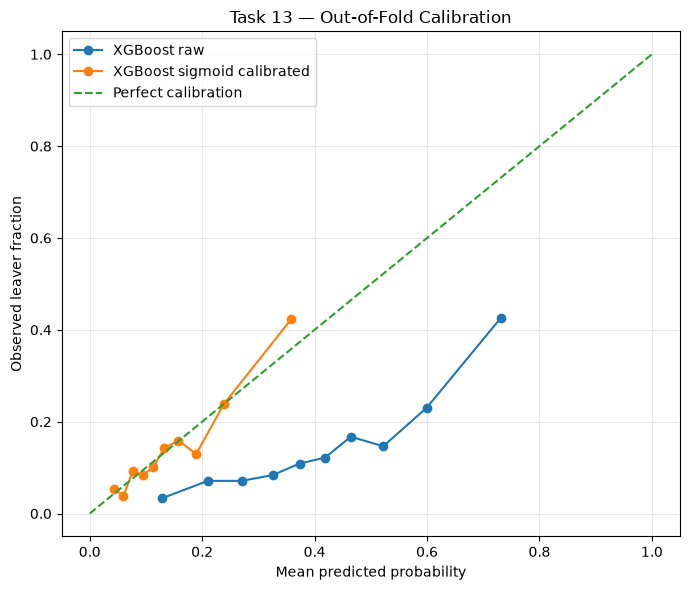

Saved Task 13 report, summary, comparison, tuning log, fold metrics, calibration table and plot.


In [13]:
# Persist report evidence, tuning log, summary and calibration plot.
fold_metrics = pd.DataFrame(fold_rows)
tuning_log = pd.DataFrame(tuning_rows)

# Record the final full-data parameter-selection search separately.
final_search_rows = []
for i, params in enumerate(final_search.cv_results_["params"]):
    final_search_rows.append({
        "model": "XGBoost",
        "outer_fold": "FULL_DATA_FINAL_SELECTION",
        "parameters": json.dumps(params, sort_keys=True),
        "inner_cv_mean_pr_auc": final_search.cv_results_["mean_test_score"][i],
        "inner_cv_sd_pr_auc": final_search.cv_results_["std_test_score"][i],
        "inner_train_mean_pr_auc": final_search.cv_results_["mean_train_score"][i],
        "selected": params == final_search.best_params_,
    })
tuning_log = pd.concat([tuning_log, pd.DataFrame(final_search_rows)], ignore_index=True)

# Add supplied benchmark context without treating reference values as local measurements.
benchmark_map = {
    "Logistic Regression (balanced)": "Logistic Regression (class_weight=balanced)",
    "Decision Tree (depth 4, balanced)": "Decision Tree (depth 4, balanced)",
    "Dummy": "Dummy (always stays)",
}
comparison["reference_roc_auc"] = np.nan
comparison["reference_pr_auc"] = np.nan
benchmark_lookup = benchmarks.set_index("model")
for idx, row in comparison.iterrows():
    reference_name = benchmark_map.get(row["model"])
    if reference_name in benchmark_lookup.index:
        comparison.loc[idx, "reference_roc_auc"] = benchmark_lookup.loc[reference_name, "roc_auc_mean"]
        comparison.loc[idx, "reference_pr_auc"] = benchmark_lookup.loc[reference_name, "pr_auc_mean"]

comparison.to_csv(REPORTS_DIR/"task13_model_comparison.csv", index=False)
fold_metrics.to_csv(REPORTS_DIR/"task13_fold_metrics.csv", index=False)
tuning_log.to_csv(REPORTS_DIR/"task13_tuning_log.csv", index=False)
calibration_comparison.to_csv(REPORTS_DIR/"task13_calibration_comparison.csv", index=False)

raw_xgb_metrics = calculate_metrics(y, candidate_oof["XGBoost"])
cal_xgb_metrics = calculate_metrics(y, calibrated_oof)
logistic_metrics = calculate_metrics(y, baseline_oof["Logistic Regression (balanced)"])
lgb_metrics = calculate_metrics(y, candidate_oof["LightGBM"])
rf_reference = benchmarks.loc[benchmarks["model"].str.contains("Random Forest", case=False)].iloc[0]

summary = {
    "task": "Task 13 — Attrition Model V2",
    "dataset": {
        "rows": int(len(df)), "leavers": int(y.sum()),
        "stayers": int((y == 0).sum()), "leaver_rate": float(y.mean()),
        "predictor_count": int(X.shape[1]),
        "numeric_predictor_count": len(numeric_columns),
        "categorical_predictor_count": len(categorical_columns),
    },
    "evaluation_protocol": {
        "outer_cv": "StratifiedKFold(n_splits=5, shuffle=True, random_state=42)",
        "tuning_cv": "3-fold stratified CV inside each outer training fold",
        "tuning_metric": "average_precision",
        "same_outer_folds_as_task3": True,
        "nested_tuning": True,
    },
    "task3_logistic_regression_pooled_oof": logistic_metrics,
    "lightgbm_nested_pooled_oof": lgb_metrics,
    "xgboost_nested_pooled_oof_raw": raw_xgb_metrics,
    "xgboost_nested_pooled_oof_sigmoid_calibrated": cal_xgb_metrics,
    "supplied_random_forest_reference": {
        "roc_auc": float(rf_reference["roc_auc_mean"]),
        "pr_auc": float(rf_reference["pr_auc_mean"]),
    },
    "improvement_vs_task3_logistic": {
        "roc_auc": float(raw_xgb_metrics["roc_auc"] - logistic_metrics["roc_auc"]),
        "pr_auc": float(raw_xgb_metrics["pr_auc"] - logistic_metrics["pr_auc"]),
    },
    "final_model": {
        "version": "attrition-v2",
        "algorithm": "XGBoost",
        "best_parameters": final_search.best_params_,
        "full_data_cv_best_average_precision_selection_only": float(final_search.best_score_),
        "calibration": "sigmoid",
        "artifact": "models/attrition/attrition-v2/model.joblib",
    },
    "limitations": [
        "Internal cross-validation is not prospective deployment validation.",
        "Supplied benchmark results may differ in feature or environment details.",
        "The 0.50 threshold is retained for comparison and is not an operational HR threshold.",
        "Use model scores only as decision support for supportive human review.",
    ],
}
with open(REPORTS_DIR/"task13_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

report_text = f'''# Task 13 — Attrition Model V2: Honest Baseline Comparison

## Dataset
- Labelled snapshots: **{len(df):,}**
- Leavers: **{int(y.sum()):,} ({y.mean():.2%})**
- Stayers: **{int((y == 0).sum()):,} ({(y == 0).mean():.2%})**
- Predictors: **{X.shape[1]}** ({len(numeric_columns)} numeric, {len(categorical_columns)} categorical)

## Evaluation protocol
The outer evaluation uses the Task 3 folds: `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`. Hyperparameters are tuned only inside each outer training partition using 3-fold stratified CV and average precision. Preprocessing is fitted inside each fold.

## Pooled out-of-fold results
| Model | ROC-AUC | PR-AUC | Precision @ 0.50 | Recall @ 0.50 | F1 @ 0.50 | Brier |
|---|---:|---:|---:|---:|---:|---:|
| Task 3 Logistic Regression | {logistic_metrics['roc_auc']:.4f} | {logistic_metrics['pr_auc']:.4f} | {logistic_metrics['precision_at_050']:.4f} | {logistic_metrics['recall_at_050']:.4f} | {logistic_metrics['f1_at_050']:.4f} | {logistic_metrics['brier']:.4f} |
| LightGBM V2 | {lgb_metrics['roc_auc']:.4f} | {lgb_metrics['pr_auc']:.4f} | {lgb_metrics['precision_at_050']:.4f} | {lgb_metrics['recall_at_050']:.4f} | {lgb_metrics['f1_at_050']:.4f} | {lgb_metrics['brier']:.4f} |
| XGBoost V2 raw | {raw_xgb_metrics['roc_auc']:.4f} | {raw_xgb_metrics['pr_auc']:.4f} | {raw_xgb_metrics['precision_at_050']:.4f} | {raw_xgb_metrics['recall_at_050']:.4f} | {raw_xgb_metrics['f1_at_050']:.4f} | {raw_xgb_metrics['brier']:.4f} |
| XGBoost V2 sigmoid calibrated | {cal_xgb_metrics['roc_auc']:.4f} | {cal_xgb_metrics['pr_auc']:.4f} | {cal_xgb_metrics['precision_at_050']:.4f} | {cal_xgb_metrics['recall_at_050']:.4f} | {cal_xgb_metrics['f1_at_050']:.4f} | {cal_xgb_metrics['brier']:.4f} |

## Improvement and benchmark context
Raw XGBoost improved ROC-AUC by **{raw_xgb_metrics['roc_auc']-logistic_metrics['roc_auc']:+.4f}** and PR-AUC by **{raw_xgb_metrics['pr_auc']-logistic_metrics['pr_auc']:+.4f}** over the Task 3 Logistic Regression baseline. The supplied Random Forest reference is ROC-AUC **{rf_reference['roc_auc_mean']:.3f}** and PR-AUC **{rf_reference['pr_auc_mean']:.3f}**. The XGBoost result is above that reference by **{raw_xgb_metrics['roc_auc']-rf_reference['roc_auc_mean']:+.4f}** ROC-AUC and **{raw_xgb_metrics['pr_auc']-rf_reference['pr_auc_mean']:+.4f}** PR-AUC. This is a reference comparison, not a same-run Random Forest evaluation.

## Tuning
The XGBoost grid tested `max_depth` {{2, 3}} and `n_estimators` {{150, 300}}. Learning rate was fixed at 0.05; subsample and column sample at 0.8; L2 regularization at 1.0. The final full-data selection chose `{final_search.best_params_}`. The full-data CV score is for final parameter selection only, not an unbiased performance estimate. See `task13_tuning_log.csv`.

## Calibration
Raw XGBoost Brier score: **{calibration_summary(y, candidate_oof['XGBoost'])['brier']:.4f}**; sigmoid-calibrated Brier score: **{calibration_summary(y, calibrated_oof)['brier']:.4f}**. Raw log loss: **{calibration_summary(y, candidate_oof['XGBoost'])['log_loss']:.4f}**; calibrated log loss: **{calibration_summary(y, calibrated_oof)['log_loss']:.4f}**. Calibration improved these probability-error measures in the nested OOF check. The 0.50 threshold is not an operational intervention threshold; calibration shifts the probability scale and very few calibrated predictions exceed 0.50.

## Versioned artifact
- Version: `attrition-v2`
- Artifact: `models/attrition/attrition-v2/model.joblib`
- Metadata: `models/attrition/attrition-v2/metadata.json`
- Calibration: sigmoid using 5-fold `CalibratedClassifierCV`.

## Limitations and responsible use
This is internal validation on one historical dataset, not prospective validation. Benchmark values may differ due to feature and environment differences. Model scores should support voluntary, supportive human review only and must not independently determine hiring, promotion, compensation, discipline, or termination.
'''
(REPORTS_DIR/"task13_attrition_model_v2_report.md").write_text(report_text, encoding="utf-8")

fig, ax = plt.subplots(figsize=(7, 6))
for label, probabilities in [
    ("XGBoost raw", candidate_oof["XGBoost"]),
    ("XGBoost sigmoid calibrated", calibrated_oof),
]:
    fraction_positive, mean_predicted = calibration_curve(
        y, probabilities, n_bins=10, strategy="quantile"
    )
    ax.plot(mean_predicted, fraction_positive, marker="o", label=label)
ax.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed leaver fraction")
ax.set_title("Task 13 — Out-of-Fold Calibration")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(EVIDENCE_DIR/"task13_calibration_comparison.png", dpi=180, bbox_inches="tight")
plt.show()
print("Saved Task 13 report, summary, comparison, tuning log, fold metrics, calibration table and plot.")

## Interpretation and limitations

Use the **nested outer-fold results** as the performance estimate. The final full-data CV score is used only to choose parameters for the saved artifact and must not be described as an unbiased test score.

Sigmoid calibration improved Brier score and log loss in the nested out-of-fold check, but it changed the probability scale. The fixed 0.50 threshold therefore produces very few positive classifications; it is not an operational HR threshold. No intervention threshold was optimized.

The model is a decision-support signal for supportive human review only. It must not independently determine hiring, promotion, compensation, discipline or termination.